### Задача: 
Проведеем прямую y = mx + b через экспериментальные точки

In [13]:
import numpy as np
x = np.array([0, 1, 2, 3])
y = np.array([-1, 0.2, 0.9, 2.1])

# Перепишем линейное уравнение y = mx + b как y = Ap, где A = [[x 1]] и p = [[m], [c]]

A = np.vstack([x, np.ones(len(x))]).T


In [14]:
m, c = np.linalg.lstsq(A, y, rcond=None)[0]
print(m, c)

0.9999999999999999 -0.9499999999999995


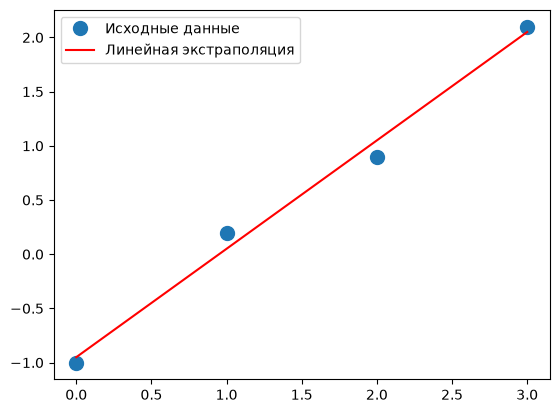

In [15]:
import matplotlib.pyplot as plt
plt.plot(x, y, 'o', label='Исходные данные', markersize=10)
plt.plot(x, m*x + c, 'r', label='Линейная экстраполяция')
plt.legend()
plt.show()

### 1.1.2 Пример

Пусть $x$, $y$ — векторы длиной $n > 3$ (точек больше 3). Задача заключается в построении экстраполяционного полинома второго порядка (параболы). Таким образом, необходимо найти коэффициенты полинома $a$, $b$, $c$ по методу наименьших квадратов. Данные могут быть получены в результате измерений. Покажем пример генерации данных случайным образом и загрузки их из файла.

In [20]:
from numpy import * 
from numpy.random import * 

# генерируем случайные x и y
delta = 1.0 
x = linspace(-5,5,11)
y = x**2 + delta*(rand(11)-0.5)
x += delta*(rand(11)-0.5)

# записываем данные в файл
x.tofile('x_data.txt', '\n')
y.tofile('y_data.txt', '\n')

# читаем данные из файла
x = fromfile('x_data.txt', sep='\n', dtype=float)
y = fromfile('y_data.txt', sep='\n', dtype=float)

print(x)
print(y)

[-4.96048542 -3.72199522 -2.91790337 -1.64718619 -1.38099551  0.35168796
  0.99299112  2.08088158  3.22969047  4.2425564   5.2203182 ]
[25.18728123 15.91155411  9.09615958  3.82736097  0.8707779   0.49413671
  0.91570348  3.97186281  8.52135166 16.19822232 24.94480653]


/var/folders/5y/zskm6qxx0g92yclb282l8gv40000gn/T/ipykernel_13024/2661495151.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


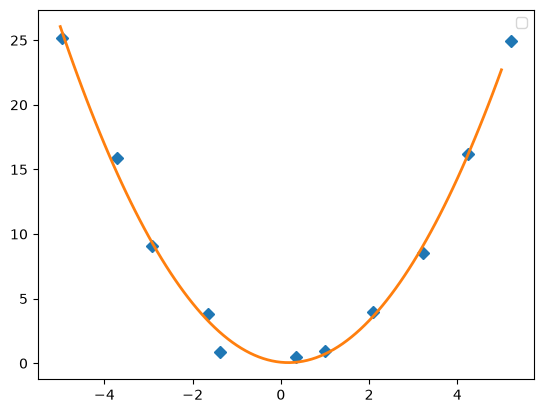

In [21]:
# Нахождение коэффициентов функции вида y = ax^2 + bx + с методом наименьших квадратов
# задаем вектор m = [x**2, x, E]

m = vstack((x**2, x, ones(11))).T
# находим коэффициенты при составляющих вектора m
s = np.linalg.lstsq(m, y, rcond = None)[0]
# на отрезке [-5, 5]
x_prec = linspace(-5, 5, 101)
# рисуем точки
plt.plot(x, y, 'D')
# рисуем кривую вида y = ax^2 + bx + c, подставляя из решения кофэффициенты s[0], s[1], s[2]
plt.plot(x_prec, s[0]*x_prec**2 + s[1]*x_prec + s[2], '-', lw=2)
plt.legend()
plt.show()